# Propagation in inhomogeneous media: the wave propagation method (WPM)

The FFT propagators from notebook 01 assume a homogeneous medium. The **wave
propagation method** by Brenner and Singer (`pyoptics.wpm`) extends the idea to
media with a spatially varying refractive index $n(x, y, z)$: the field is
propagated in thin slices $\Delta z$. In each slice it is decomposed into plane
waves, and **every plane wave is propagated at every location with the local**
$k_z(x, y) = \sqrt{n(x, y)^2 k_0^2 - k_x^2 - k_y^2}$:

$$U(x, y, z + \Delta z) = \sum_{k_x, k_y} \tilde U(k_x, k_y; z)\,
  e^{i(k_x x + k_y y)}\, e^{i k_z(x, y)\,\Delta z}.$$

Summed directly, this costs $O(N_x^2 N_y^2)$ per step (`method="direct"`). If the
slice consists of a few materials only, the same sum can be rearranged: for each
distinct index $n_q$, the whole spectrum is propagated with the homogeneous
transfer function of $n_q$ by FFT, and each pixel takes the result of its own
material (`method="levels"`, the "fast WPM"). Both give the same result to rounding
errors; the default `method="auto"` picks the cheaper one. The index is sampled in
the middle of each slice by default (`n_sampling`).

For problems that are invariant in $y$ ($xz$ cuts through waveguides, cylindrical
lenses, ...) the field can be one-dimensional: pass `y=None`. `wpm_propagate_z()`
steps through a list of $z$ positions and returns the field at all of them.

Sampling: the plane wave decomposition contains all propagating waves of the
densest medium only if $\Delta x \leq \lambda / (2 n_\mathrm{max})$
(`max_sampling_distance()`).

Note: `wpm.pyx` is a Cython extension and is compiled when `pyoptics` is
installed.


In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics.wpm import wpm_propagate_z, max_sampling_distance
from pyoptics import propagators as prop
from pyoptics.utils import grid1d

plt.rcParams.update({"figure.dpi": 100, "image.origin": "lower", "font.size": 11})

wl = 1.0                 # wavelength [µm]
k0 = 2*np.pi/wl

def run_wpm(n_xz, u0, x, z_vals, **kwargs):
    """Propagate u0(x) through n(x, z) (y-invariant) and return the field at all z_vals.
    n_xz(X, z) returns the index on the grid X for the slice at z."""
    return wpm_propagate_z(lambda X, Y, z: n_xz(X, z), u0, x, None, z_vals, wl, **kwargs)

def plot_xz(ax, U, x, z_vals, n_map=None, title="", xlim=None, gamma=1.0):
    I = np.abs(U)**2
    ax.imshow(((I/I.max())**gamma).T, extent=(z_vals[0], z_vals[-1], x[0], x[-1]), aspect="auto",
              cmap="inferno", interpolation="bilinear")
    if n_map is not None:
        ax.contour(z_vals, x, n_map.T, levels=np.unique(np.round(n_map, 4))[:-1] + 1e-4,
                   colors="w", linewidths=0.6, alpha=0.7)
    ax.set_xlabel("$z$ [µm]"); ax.set_ylabel("$x$ [µm]"); ax.set_title(title)
    if xlim:
        ax.set_ylim(*xlim)

## 1. Test: homogeneous medium

In a homogeneous medium, the WPM must give exactly the result of the
Rayleigh-Sommerfeld propagator (transfer function with $n$). The comparison uses
the 2D propagator on a grid with two $y$ rows (a $y$-invariant field). We also time
both implementations of the WPM sum: with only one index value, `"levels"` needs a
single FFT pair per step.


dx = 0.250 µm, max. dx for n = 1.5: 0.333 µm


80 WPM steps, method='direct': 0.386 s
80 WPM steps, method='levels': 0.023 s
max. deviation from RS: 7.6e-15


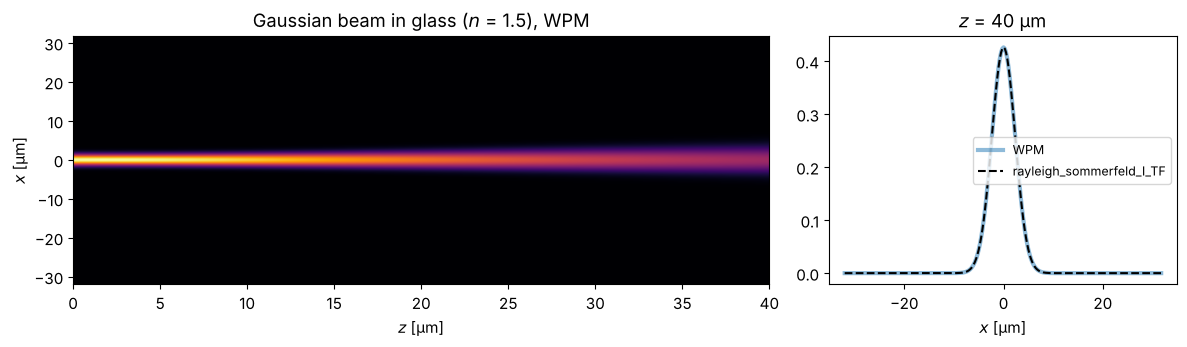

In [2]:
L, N = 64.0, 256
x = grid1d(-L/2, L/2, N)
print(f"dx = {x[1] - x[0]:.3f} µm, max. dx for n = 1.5: {max_sampling_distance(wl, 1.5):.3f} µm")
u0 = np.exp(-x**2/2.0**2)
z_vals = np.linspace(0, 40, 81)
n_glass = lambda X, z: 1.5*np.ones_like(X)

for method in ("direct", "levels"):
    t0 = time.time()
    U_wpm = run_wpm(n_glass, u0, x, z_vals, method=method)
    print(f"80 WPM steps, method='{method}': {time.time() - t0:.3f} s")
y2 = grid1d(-1, 1, 2)    # two y rows: problem invariant in y
U_rs, _, _ = prop.rayleigh_sommerfeld_I_TF(np.tile(u0, (2, 1)).astype(complex), x, y2, z_vals[-1], wl, n=1.5)
print(f"max. deviation from RS: {np.abs(U_wpm[-1] - U_rs[0]).max():.1e}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [2, 1]})
plot_xz(axes[0], U_wpm, x, z_vals, title="Gaussian beam in glass ($n$ = 1.5), WPM")
axes[1].plot(x, np.abs(U_wpm[-1])**2, lw=3, alpha=0.5, label="WPM")
axes[1].plot(x, np.abs(U_rs[0])**2, "k--", label="rayleigh_sommerfeld_I_TF")
axes[1].set_xlabel("$x$ [µm]"); axes[1].set_title(f"$z$ = {z_vals[-1]:.0f} µm"); axes[1].legend(fontsize=9)
fig.tight_layout()


## 2. Gradient-index (GRIN) lens

A parabolic index profile $n(x) = n_0\,(1 - g^2 x^2/2)$ acts like a continuous
sequence of weak lenses. Rays oscillate sinusoidally about the axis,
$x(z) = x_0\cos(gz)$, with the *pitch length* $P = 2\pi/g$. A Gaussian beam with the
radius $w_m = \sqrt{2/(k_0 n_0 g)}$ is the fundamental mode of the profile and
propagates unchanged. A narrower beam "breathes" with the period $P/2$, an offset
one swings like the ray of geometrical optics. (Shown is $I^{0.6}$, so that the
weak parts stay visible.) The profile is continuous, so almost every pixel has
its own index, and `method="auto"` uses the direct sum here.

The offset beam swings somewhat more slowly than the paraxial ray $x_0\cos(gz)$:
at 8 µm displacement it is no longer strictly paraxial.

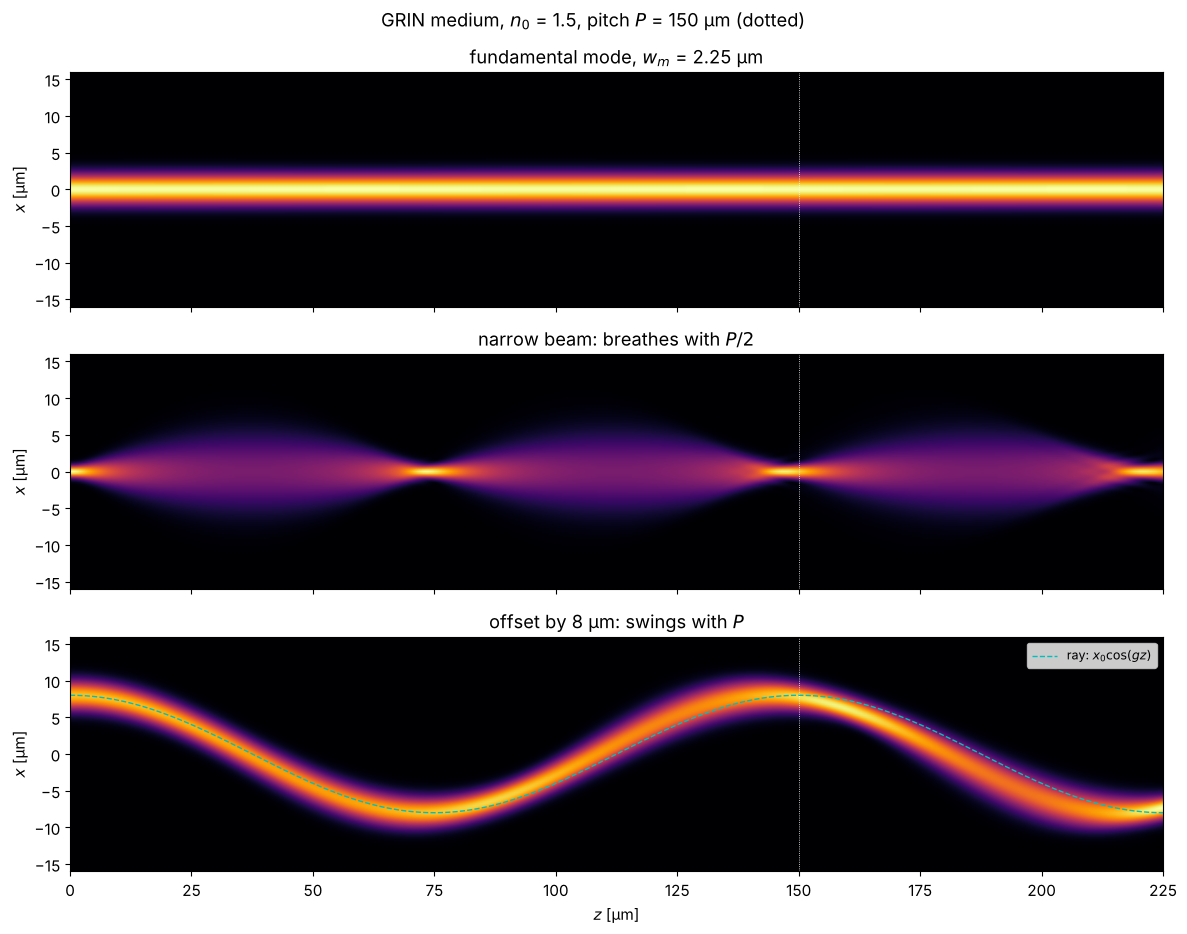

In [3]:
n0, P = 1.5, 150.0
g = 2*np.pi/P
# clip the profile at n = 1.3 near the edge, otherwise the index would drop below 1 at the window edge:
n_grin = lambda X, z: np.maximum(n0*(1 - g**2*X**2/2), 1.3)
w_m = np.sqrt(2/(k0*n0*g))
z_vals = np.linspace(0, 1.5*P, 451)

beams = ((np.exp(-x**2/w_m**2), f"fundamental mode, $w_m$ = {w_m:.2f} µm"),
         (np.exp(-x**2/(w_m/2.5)**2), "narrow beam: breathes with $P/2$"),
         (np.exp(-(x - 8)**2/w_m**2), "offset by 8 µm: swings with $P$"))
fig, axes = plt.subplots(3, 1, figsize=(12, 9.5), sharex=True)
for ax, (u, title) in zip(axes, beams):
    U = run_wpm(n_grin, u, x, z_vals)
    plot_xz(ax, U, x, z_vals, title=title, xlim=(-16, 16), gamma=0.6)
    for m in range(1, 2):
        ax.axvline(m*P, color="w", lw=0.6, ls=":")
axes[2].plot(z_vals, 8*np.cos(g*z_vals), "c--", lw=1, label="ray: $x_0\\cos(gz)$")
axes[2].legend(loc="upper right", fontsize=9)
for ax in axes[:2]:
    ax.set_xlabel("")
fig.suptitle(f"GRIN medium, $n_0$ = {n0}, pitch $P$ = {P:.0f} µm (dotted)")
fig.tight_layout()

## 3. Step-index waveguide

A core with a higher index traps light by total internal reflection. In the wave
picture: the core supports guided modes whose field decays evanescently in the
cladding. A Gaussian beam that does not exactly match the fundamental mode excites
several modes, which travel with different propagation constants and beat against
each other. Without a core (bottom) the beam simply diffracts apart. With two index values,
`method="auto"` uses the fast `"levels"` sum.

NA = 0.344, V parameter (half core width) = 6.49 -> about 5 guided modes


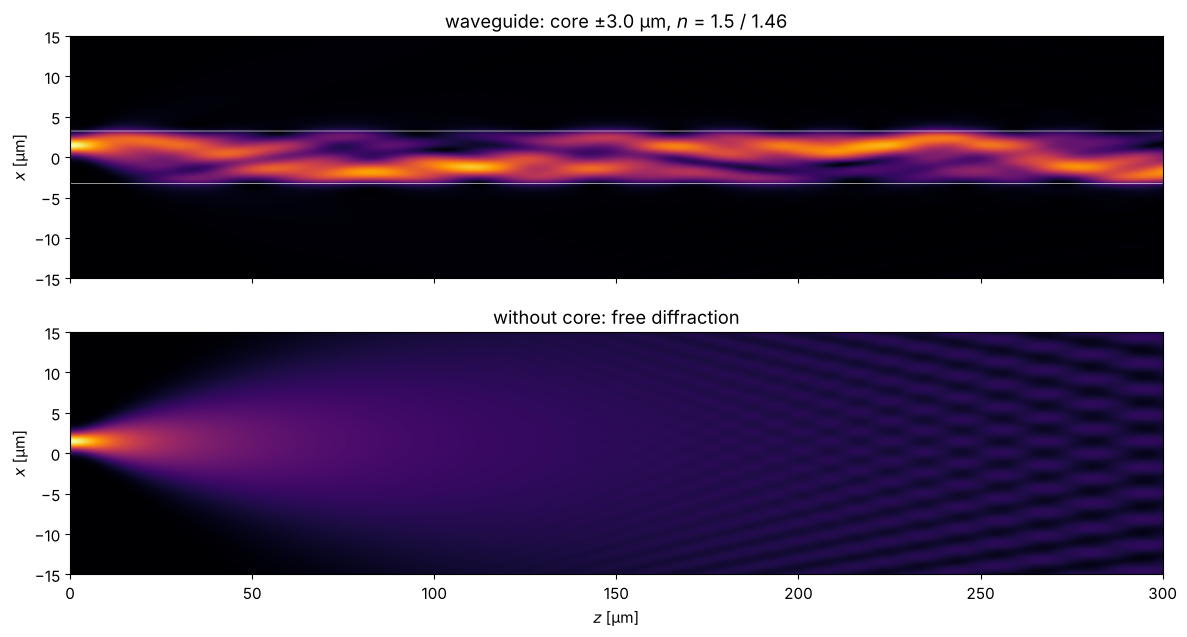

In [4]:
core, n_core, n_clad = 3.0, 1.50, 1.46
n_wg = lambda X, z: np.where(np.abs(X) <= core, n_core, n_clad)
NA_wg = np.sqrt(n_core**2 - n_clad**2)
V = k0*core*NA_wg
print(f"NA = {NA_wg:.3f}, V parameter (half core width) = {V:.2f} -> about {int(2*V/np.pi) + 1} guided modes")
z_vals = np.linspace(0, 300, 601)
u_in = np.exp(-(x - 1.5)**2/1.2**2)   # narrow and slightly offset: excites several modes

U_wg = run_wpm(n_wg, u_in, x, z_vals)
U_free = run_wpm(lambda X, z: n_clad*np.ones_like(X), u_in, x, z_vals)
n_map = np.array([n_wg(x, z) for z in z_vals])

fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
plot_xz(axes[0], U_wg, x, z_vals, n_map=n_map, title=f"waveguide: core ±{core} µm, $n$ = {n_core} / {n_clad}",
        xlim=(-15, 15), gamma=0.6)
plot_xz(axes[1], U_free, x, z_vals, title="without core: free diffraction", xlim=(-15, 15), gamma=0.6)
axes[0].set_xlabel("")
fig.tight_layout()

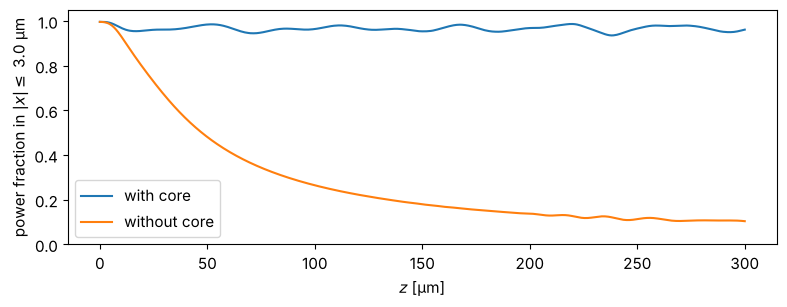

In [5]:
P_core = [np.sum(np.abs(U[np.abs(x) <= core])**2)/np.sum(np.abs(U)**2) for U in U_wg]
P_free = [np.sum(np.abs(U[np.abs(x) <= core])**2)/np.sum(np.abs(U)**2) for U in U_free]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(z_vals, P_core, label="with core")
ax.plot(z_vals, P_free, label="without core")
ax.set_xlabel("$z$ [µm]"); ax.set_ylabel("power fraction in $|x| \\leq$ " + f"{core} µm")
ax.set_ylim(0, 1.05); ax.legend()
fig.tight_layout()

Part of the power is lost at the beginning: it belongs to radiation modes that are
not guided and radiate sideways. (At the window edge, this light re-enters on the
other side because of the periodic boundary conditions of the plane-wave
decomposition. For longer distances, an absorbing index $n + i\kappa$ near the
window edges takes it out.)

## 4. A thick cylindrical lens

Finally, a case the WPM is made for: a large index step at a curved surface. A
plano-convex cylindrical glass lens ($n = 1.5$) with radius of curvature $R$ has the
focal length $f = R/(n-1)$, measured from the principal plane, which for a
plano-convex lens lies at the vertex of the curved surface. With $\pm 30$ µm at
$R = 60$ µm, however, the aperture is anything but paraxial. The WPM shows the
focus including spherical aberration: marginal rays cross the axis too early, the
intensity maximum lies well before the paraxial focus, and a caustic forms in
front of the focus.

699 WPM steps with N = 512: 0.3 s
paraxial focus at z = 135.0 µm, intensity maximum at z = 119.7 µm


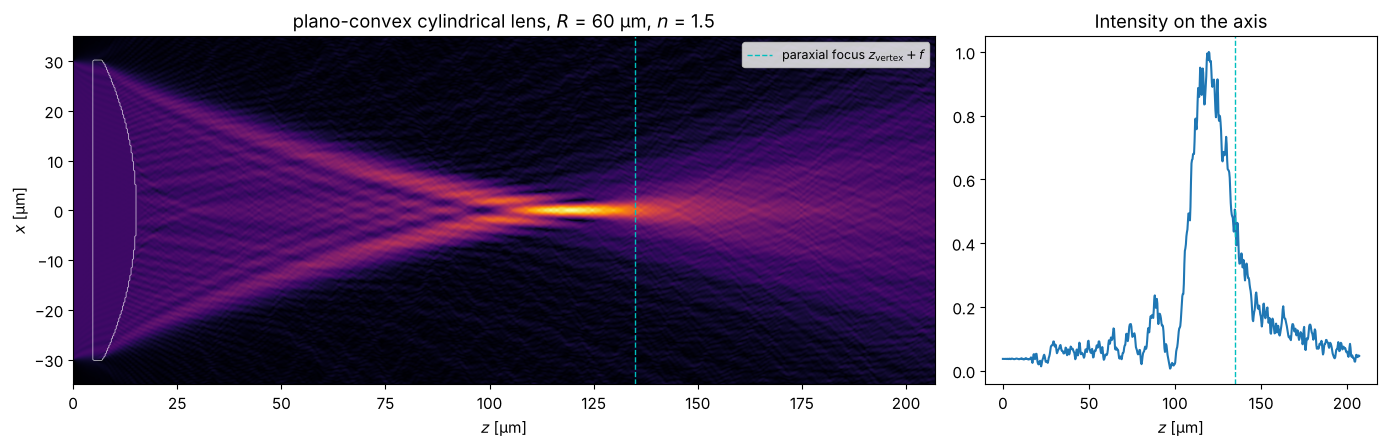

In [6]:
L4, N4 = 96.0, 512
x4 = grid1d(-L4/2, L4/2, N4)
R_lens, n_lens, z_front, half_ap = 60.0, 1.5, 5.0, 30.0
sag = R_lens - np.sqrt(np.maximum(R_lens**2 - x4**2, 0))
t_center = R_lens - np.sqrt(R_lens**2 - half_ap**2) + 2.0   # centre thickness
z_vertex = z_front + t_center   # vertex of the curved back surface

def n_lens_func(X, z):
    # flat front surface at z_front, curved back surface: z <= z_vertex - sag(x)
    s = R_lens - np.sqrt(np.maximum(R_lens**2 - X**2, 0))
    inside = (z >= z_front) & (z <= z_vertex - s) & (np.abs(X) <= half_ap)
    return np.where(inside, n_lens, 1.0)

f = R_lens/(n_lens - 1)
z_vals = np.linspace(0, z_vertex + 1.6*f, 700)
u_plane = np.where(np.abs(x4) <= half_ap, 1.0, 0.0)*np.exp(-(x4/40)**8)  # plane wave with soft edges
t0 = time.time()
U_lens = run_wpm(n_lens_func, u_plane, x4, z_vals)
print(f"{len(z_vals) - 1} WPM steps with N = {N4}: {time.time() - t0:.1f} s")
n_map = np.array([n_lens_func(x4, z) for z in z_vals])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [2.2, 1]})
plot_xz(axes[0], U_lens, x4, z_vals, n_map=n_map, title=f"plano-convex cylindrical lens, $R$ = {R_lens:.0f} µm, $n$ = {n_lens}",
        xlim=(-35, 35), gamma=0.5)
axes[0].axvline(z_vertex + f, color="c", ls="--", lw=1, label="paraxial focus $z_\\mathrm{vertex} + f$")
axes[0].legend(loc="upper right", fontsize=9)
I_axis = np.abs(U_lens[:, N4//2])**2
axes[1].plot(z_vals, I_axis/I_axis.max())
axes[1].axvline(z_vertex + f, color="c", ls="--", lw=1)
axes[1].set_xlabel("$z$ [µm]"); axes[1].set_title("Intensity on the axis")
fig.tight_layout()
z_peak = z_vals[np.argmax(I_axis)]
print(f"paraxial focus at z = {z_vertex + f:.1f} µm, intensity maximum at z = {z_peak:.1f} µm")